In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')


In [ ]:
df= pd.read_csv('ai4i2020.csv')
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.shape


(10000, 14)

In [ ]:
print(df.columns)
df.info()


Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF      

In [ ]:
print(f'No. of NaN Values: {df.isna().sum().sum()}')
print(f'No. of duplicated Values: {df.duplicated().sum()}')
print(f'Data Types:\n{df.dtypes.value_counts()}')


No. of NaN Values: 0
No. of duplicated Values: 0
Data Types:
int64      9
float64    3
str        2
Name: count, dtype: int64


In [ ]:
print(df['Machine failure'].value_counts())


Machine failure
0    9661
1     339
Name: count, dtype: int64


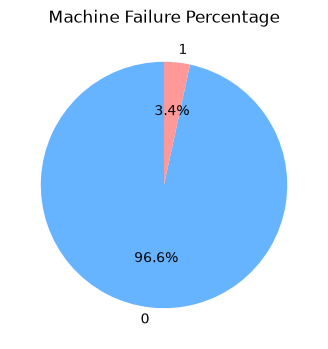

In [ ]:
plt.figure(figsize=(6,4))
df['Machine failure'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999']
)
plt.title('Machine Failure Percentage')
plt.ylabel('')
plt.show()


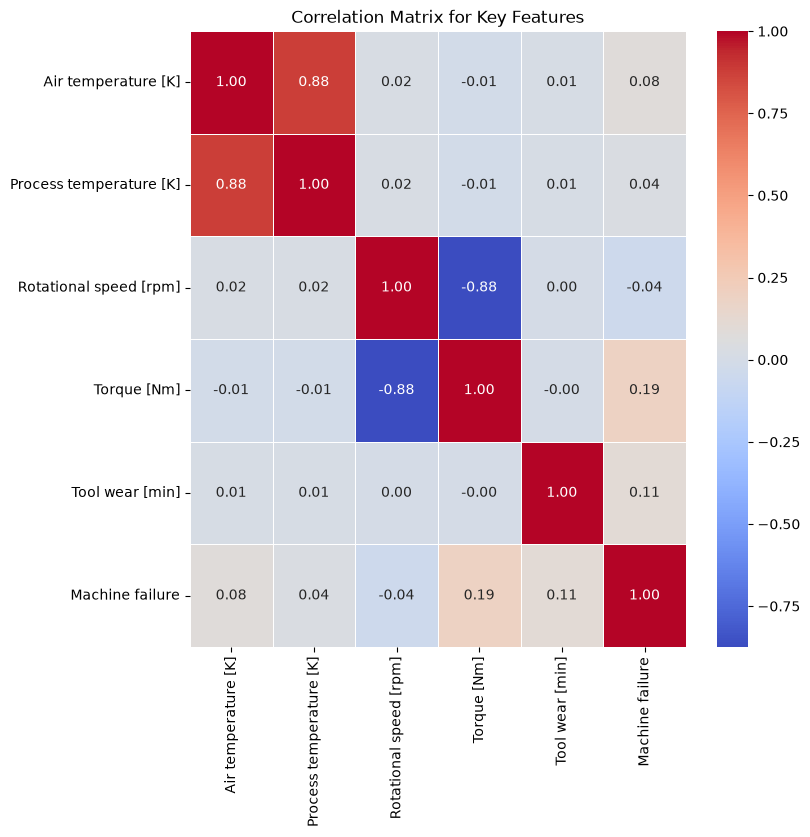

Machine failure            1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [ ]:
num_cols= [ 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]','Machine failure']
corr= df[num_cols].corr()

plt.figure(figsize=(8,8))
sns.heatmap(
    corr, annot=True, cmap='coolwarm', fmt= '.2f', linewidths=0.5)

plt.title('Correlation Matrix for Key Features')
plt.show()

print(corr['Machine failure'].sort_values(ascending=False))
num_cols.remove('Machine failure')
print(num_cols)



Text(0.5, 1.0, 'Rotational speed [rpm] Distibution')

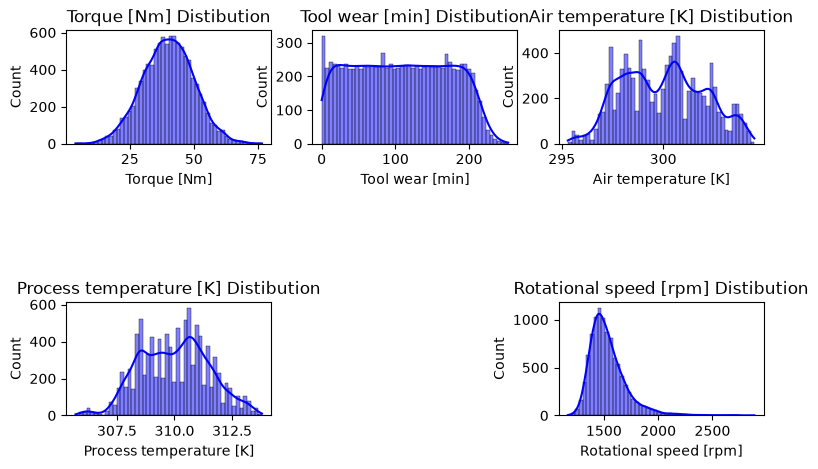

In [ ]:
plt.figure(figsize=(9, 5))
plt.subplot(3, 3, 1)
sns.histplot(df['Torque [Nm]'], kde=True, bins= 50, color='blue')
plt.title('Torque [Nm] Distibution')

plt.subplot(3, 3, 2)
sns.histplot(df['Tool wear [min]'], kde=True, bins= 50, color='blue')
plt.title('Tool wear [min] Distibution')

plt.subplot(3, 3, 3)
sns.histplot(df['Air temperature [K]'], kde=True, bins= 50, color='blue')
plt.title('Air temperature [K] Distibution')


plt.subplot(3, 3, 7)
sns.histplot(df['Process temperature [K]'], kde=True, bins= 50, color='blue')
plt.title('Process temperature [K] Distibution')

plt.subplot(3, 3, 9)
sns.histplot(df['Rotational speed [rpm]'], kde=True, bins= 50, color='blue')
plt.title('Rotational speed [rpm] Distibution')


In [ ]:
failure_cols= ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df['Total Failures']= df[failure_cols].sum(axis=1)

print(df['Total Failures'].value_counts())


Total Failures
0    9652
1     324
2      23
3       1
Name: count, dtype: int64


In [ ]:
cat_cols= df.select_dtypes('str').columns.tolist()
print(cat_cols)
df[cat_cols]


['Product ID', 'Type']


,Product ID,Type
0,M14860,M
1,L47181,L
2,L47182,L
3,L47183,L
4,L47184,L
...,...,...
9995,M24855,M
9996,H39410,H
9997,M24857,M
9998,H39412,H


In [ ]:
cat_cols.remove('Product ID')
print(cat_cols)


['Type']


In [ ]:
X= df.drop(columns=['UDI', 'Product ID', 'Machine failure'])
y=df['Machine failure']

X_train, X_test, y_train, y_test= train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
preprocessor= ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), num_cols)
])


In [ ]:
svm_smote_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", SVC(
        C=1.0,
        kernel='rbf',
        class_weight='balanced',
        probability=True
    ))
])
svm_smote_pipeline.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](12,)","['Type','Air temperature [K]','Process temperature [K]',...,'OSF','RNF', 'Total Failures']"
n_features_in_,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [82]:
y_pred= svm_smote_pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall:", round(recall_score(y_test,y_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 97.4 %
Precision: 57.63 %
Recall: 55.74 %
F1 Score: 56.67 %

Confusion Matrix:
[[1914   25]
 [  27   34]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1939
           1       0.58      0.56      0.57        61

    accuracy                           0.97      2000
   macro avg       0.78      0.77      0.78      2000
weighted avg       0.97      0.97      0.97      2000

